# Proyecto 19. Acelerador lineal

**Área:** Aceleradores — **Nivel:** III

Linac de protones de tubos de deriva: diseño de celdas βλ, dinámica longitudinal de un paquete, estabilidad de fase, oscilaciones de sincrotrón, error de frecuencia y electrones.

Este notebook contiene el código completo del proyecto (las mismas instrucciones que `src/*.py`), dividido en celdas. Ejecútelo de arriba abajo desde la carpeta del proyecto. El informe completo está en `informe/informe.pdf`.

## 1. Configuración

In [2]:
import sys
from pathlib import Path
from IPython.display import Image, display

RAIZ = Path.cwd()                      # el notebook se ejecuta desde la carpeta del proyecto
SRC = RAIZ / "src"
sys.path.insert(0, str(SRC))           # modelo.py (y minigeant4.py en el proyecto 25)
sys.path.insert(0, str(RAIZ.parents[1]))   # modulos comunes: comun/
print("Proyecto:", RAIZ.name)

Proyecto: P19-Acelerador-lineal


In [27]:
!pip install scipy


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 11.6 MB/s  0:00:03 eta 0:00:010:01:01


## 2. Modelo físico

Funciones del modelo. La celda reescribe `src/modelo.py` con su contenido, de modo que cualquier cambio hecho aquí se usa en el resto del notebook.

**`src/modelo.py`** — Acelerador lineal de tubos de deriva: la particula gana Delta E = q V cos(phi) en cada hueco; las celdas se disenan para la particula sincrona (L_n = beta_n lambda). Dinamica longitudinal de un paquete de particulas.

In [23]:
%%writefile src/modelo.py
"""Acelerador lineal de tubos de deriva: la particula gana Delta E = q V cos(phi) en cada hueco; las celdas se disenan
para la particula sincrona (L_n = beta_n lambda). Dinamica longitudinal de un paquete de particulas."""
import numpy as np

C = 299792458.0
MASAS = {"protón": 938.27208816, "electrón": 0.51099895}


def beta_de_T(T, m):
    g = 1 + T / m
    return np.sqrt(1 - 1 / g ** 2)


def disenar(T0, Tfin, qV, phis_grados, m, lam, max_celdas=10000):
    """celdas de la particula sincrona: energia a la entrada de cada hueco y longitud de la celda siguiente"""
    T, Ts, L = T0, [], []
    for _ in range(max_celdas):
        Ts.append(T)
        T = T + qV * np.cos(np.radians(phis_grados))
        L.append(beta_de_T(T, m) * lam)
        if T >= Tfin:
            break
    return np.array(Ts), np.array(L)


def seguir(T0, dphi0_grados, L, qV, phis_grados, m, f_rf, error_f=0.0):
    """sigue particulas (arreglos T0 en MeV y desfases iniciales en grados) a traves de las celdas L (m).
    La fase en cada hueco es phi = phi_s + omega (t - t_s), con omega la frecuencia real del RF (con error relativo error_f).
    Devuelve energia y fase (grados, relativa a la cresta) en cada hueco: matrices (celdas+1, N)."""
    w = 2 * np.pi * f_rf * (1 + error_f)
    T = np.array(T0, float)
    phi = np.radians(phis_grados + np.array(dphi0_grados, float))
    TT, PP = [T.copy()], [np.degrees(phi)]
    for Ln in L:
        T = T + qV * np.cos(phi)
        T = np.maximum(T, 1e-6)
        dt = Ln / (beta_de_T(T, m) * C)
        # en el diseno, el sincrono tarda exactamente un periodo del RF de diseno por celda (L = beta lambda)
        phi = phi + w * dt - 2 * np.pi
        TT.append(T.copy())
        PP.append(np.degrees(phi))
    return np.array(TT), np.array(PP)


def avance_sincrotron(qV, phis_grados, T, m):
    """avance de fase de las oscilaciones de sincrotron por celda (rad), pequena amplitud:
    mu^2 = 2 pi qV (-sin phi_s) / (m c^2 beta^2 gamma^3)"""
    g = 1 + T / m
    b = beta_de_T(T, m)
    return np.sqrt(np.maximum(2 * np.pi * qV * (-np.sin(np.radians(phis_grados))) / (m * b ** 2 * g ** 3), 0))


def aceptancia_fase(phis_grados):
    """extremos de la separatriz en fase: phi_2 (anterior) y -phi_s (posterior) para el potencial del pendulo"""
    from scipy.optimize import brentq
    ps = np.radians(phis_grados)
    f = lambda p: np.sin(p) - p * np.cos(ps) - (np.sin(-ps) - (-ps) * np.cos(ps))
    try:
        p2 = brentq(f, -np.pi, ps)
    except ValueError:
        p2 = np.nan
    return np.degrees(p2), -phis_grados

Overwriting src/modelo.py


In [24]:
import importlib
import modelo
importlib.reload(modelo)
print('modelo cargado')

modelo cargado


## 3. Simulación y análisis

Proyecto 19: acelerador lineal de protones (tipo Alvarez) de 3 a 50 MeV.
1) diseno de las celdas para la particula sincrona y energia frente al numero de cavidades;
2) paquete de particulas: estabilidad de fase para distintas fases sincronas;
3) oscilaciones de sincrotron: avance de fase simulado frente a la teoria;
4) efecto de un error de frecuencia (sincronizacion); 5) electrones (beta ~ 1).

In [25]:
__file__ = str(SRC / "simulacion.py")   # los programas localizan las carpetas del proyecto con __file__
import sys #CONSULTAR
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[3]))
import numpy as np
import pandas as pd
from comun.proyecto import Proyecto
import modelo as M

P = Proyecto(__file__)
par = P.leer_parametros()
rng = np.random.default_rng(par["semilla"])
m = M.MASAS[par["particula"]]
f = par["f_rf_MHz"] * 1e6
lam = M.C / f
qV = par["V_gap_MV"]
T0, Tf = par["T_inicial_MeV"], par["T_final_MeV"]
res = dict(lambda_m=lam)

### 1) diseno

In [28]:
# 1) diseno
Ts, L = M.disenar(T0, Tf, qV, par["fase_referencia_grados"], m, lam)
P.guardar_csv(pd.DataFrame({"celda": np.arange(len(L)), "T_entrada_MeV": Ts, "L_celda_m": L, "beta": M.beta_de_T(Ts, m)}), "diseno_celdas")
res["diseno"] = dict(celdas=len(L), longitud_m=float(L.sum()), L_primera=float(L[0]), L_ultima=float(L[-1]),
                     gradiente_MeV_m=float((Tf - T0) / L.sum()), ganancia_por_celda=qV * np.cos(np.radians(par["fase_referencia_grados"])))
# ecuacion de la guia: E_N = E_0 + sum q V cos(phi_i), ilustrada con la fase sincrona en cada celda
filas = []
for ps in par["fases_sincronas_grados"]:
    Tsx, Lx = M.disenar(T0, Tf, qV, ps, m, lam) if ps < 90 else (None, None)
    filas.append(dict(fase_sincrona=ps, celdas=len(Lx), longitud_m=Lx.sum(), aceptancia=M.aceptancia_fase(ps)))
P.guardar_csv(pd.DataFrame([{k: (v if k != "aceptancia" else None) for k, v in f_.items()} for f_ in filas]).drop(columns="aceptancia"), "celdas_vs_fase")

  resultados diseno_celdas.csv
  resultados celdas_vs_fase.csv


### 2) paquetes para cada fase sincrona (cada uno con su propio diseno)

In [29]:
# 2) paquetes para cada fase sincrona (cada uno con su propio diseno)
h = par["haz"]
N = h["particulas"]
dphi0 = h["dispersion_fase_grados"] * rng.standard_normal(N)
dT0 = T0 * h["dispersion_energia_rel"] * rng.standard_normal(N)
filas = []
for ps in par["fases_sincronas_grados"]:
    Tsx, Lx = M.disenar(T0, Tf, qV, ps, m, lam)
    TT, PP = M.seguir(T0 + dT0, dphi0, Lx, qV, ps, m, f)
    Tsync = np.concatenate([Tsx, [Tsx[-1] + qV * np.cos(np.radians(ps))]])
    dW = TT - Tsync[:, None]
    dP = PP - ps
    capt = np.abs(dP[-1]) < 60
    acel = np.abs(dW[-1]) < 1.0                     # llegan con la energia de diseno (+-1 MeV)
    filas.append(dict(fase_sincrona=ps, celdas=len(Lx), capturadas=capt.mean(), aceleradas=acel.mean(),
                      fase_media_final_aceleradas=float(PP[-1, acel].mean()) if acel.any() else np.nan, dW_rms_final_MeV=dW[-1, capt].std() if capt.any() else np.nan,
                      dphi_rms_final=dP[-1, capt].std() if capt.any() else np.nan, dphi_rms_inicial=dP[0].std(),
                      T_medio_final=TT[-1, capt].mean() if capt.any() else np.nan))
    np.savez_compressed(P.datos / f"paquete_fase{ps}.npz", dP=dP[:, :800].astype(np.float32), dW=dW[:, :800].astype(np.float32))
EST = pd.DataFrame(filas)
P.guardar_csv(EST, "estabilidad_fase")

  resultados estabilidad_fase.csv


### 3) oscilacion de pequena amplitud con la fase de referencia

In [30]:
# 3) oscilacion de pequena amplitud con la fase de referencia
ps = par["fase_referencia_grados"]
TT, PP = M.seguir(np.array([T0]), np.array([3.0]), L, qV, ps, m, f)
dp = PP[:, 0] - ps
cruces = np.where(np.diff(np.sign(dp)) != 0)[0]
mu_teo = M.avance_sincrotron(qV, ps, Ts, m)
P.guardar_csv(pd.DataFrame({"celda": np.arange(len(dp)), "dphi": dp, "mu_teo_rad": np.append(mu_teo, mu_teo[-1])}), "oscilacion_pequena")
# avance de fase simulado: media vuelta entre cruces por cero consecutivos
filas = []
for a, b in zip(cruces[:-1], cruces[1:]):
    filas.append(dict(celda_media=(a + b) / 2, mu_sim=np.pi / (b - a), mu_teo=mu_teo[int((a + b) / 2)]))
MU = pd.DataFrame(filas)
P.guardar_csv(MU, "avance_sincrotron")
res["sincrotron"] = dict(mu_inicial_teo_grados=float(np.degrees(mu_teo[0])), mu_final_teo_grados=float(np.degrees(mu_teo[-1])),
                         amplitud_inicial=float(abs(dp[:5]).max()), amplitud_final=float(abs(dp[-10:]).max()))

  resultados oscilacion_pequena.csv
  resultados avance_sincrotron.csv


### 4) error de frecuencia

In [31]:
# 4) error de frecuencia
filas = []
for ef in par["error_frecuencia_rel"]:
    TT, PP = M.seguir(T0 + dT0, dphi0, L, qV, ps, m, f, error_f=ef)
    capt = np.abs(PP[-1] - ps) < 60
    filas.append(dict(error_f=ef, capturadas=capt.mean(), T_medio_final=TT[-1, capt].mean() if capt.any() else np.nan,
                      fase_media_final=(PP[-1, capt] - ps).mean() if capt.any() else np.nan))
    np.save(P.datos / f"fase_media_error{ef}.npy", np.median(PP - ps, axis=1).astype(np.float32))
ER = pd.DataFrame(filas)
P.guardar_csv(ER, "error_frecuencia")

  resultados error_frecuencia.csv


### 5) electrones: celdas de longitud lambda (beta ~ 1), fase fija

In [32]:
# 5) electrones: celdas de longitud lambda (beta ~ 1), fase fija
e = par["electron"]
me = M.MASAS["electrón"]
Le = np.full(e["celdas"], lam)
TT, PP = M.seguir(np.full(5, e["T_inicial_MeV"]), np.array([-40, -20, 0, 20, 40.0]), Le, qV, 0.0, me, f)
P.guardar_csv(pd.DataFrame({"celda": np.arange(len(TT)), **{f"T_fase{p:g}": TT[:, i] for i, p in enumerate([-40, -20, 0, 20, 40])},
                            **{f"fase{p:g}": PP[:, i] for i, p in enumerate([-40, -20, 0, 20, 40])}}), "electrones")
res["electrones"] = dict(T_final_cresta=float(TT[-1, 2]), deriva_fase_cresta=float(PP[-1, 2] - PP[0, 2]), T_final_40=float(TT[-1, 4]),
                         cos40=float(np.cos(np.radians(40))))
P.guardar_json("resumen", res)
print(res)
print(EST.to_string())
print(ER.to_string())
print(MU.head(8).to_string())

  resultados electrones.csv
  resultados resumen.json
{'lambda_m': 0.8511994832481544, 'diseno': {'celdas': 55, 'longitud_m': 10.586685182294357, 'L_primera': 0.07703275480161698, 'L_ultima': 0.2688735250881599, 'gradiente_MeV_m': 4.439538834932477, 'ganancia_por_celda': np.float64(0.8660254037844387)}, 'sincrotron': {'mu_inicial_teo_grados': 41.36012849295018, 'mu_final_teo_grados': 9.790683135990601, 'amplitud_inicial': 3.0, 'amplitud_final': 1.3944720149349727}, 'electrones': {'T_final_cresta': 69.92257672358407, 'deriva_fase_cresta': 3.607731677799499, 'T_final_40': 53.55138671263161, 'cos40': 0.766044443118978}}
   fase_sincrona  celdas  capturadas  aceleradas  fase_media_final_aceleradas  dW_rms_final_MeV  dphi_rms_final  dphi_rms_inicial  T_medio_final
0            -60      94    1.000000    0.996333                   -59.860294          0.154687        7.357651         14.967092      50.017995
1            -30      55    0.993000    0.991667                   -29.443613        

## 4. Figuras

Figuras del Proyecto 19 (acelerador lineal). Cada figura se guarda en `figuras/` (PNG y PDF) y se muestra debajo de su celda.

In [33]:
__file__ = str(SRC / "graficas.py")
import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parents[3]))
import numpy as np
from comun.proyecto import Proyecto
from comun import estilo

P = Proyecto(__file__)
par = P.leer_parametros()
r = P.cargar_json("resumen")

### Fig 1: diseno

  figura fig01_diseno


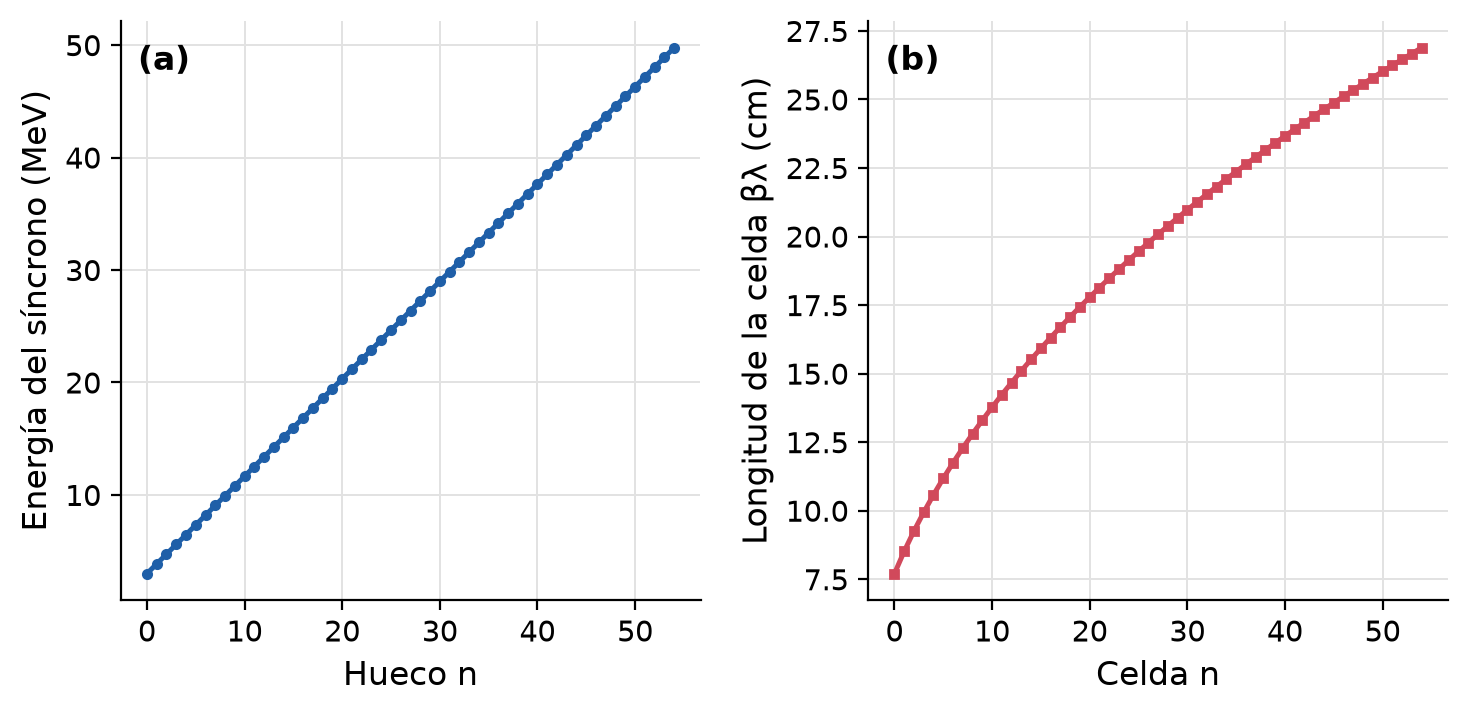

In [34]:
# Fig 1: diseno
D = P.leer_csv("diseno_celdas")
fig, axs = estilo.figura(1, 2, alto=3.7)
axs[0].plot(D.celda, D.T_entrada_MeV, "o-", ms=3)
axs[0].set_xlabel("Hueco n")
axs[0].set_ylabel("Energía del síncrono (MeV)")
estilo.letra(axs[0], "(a)", 0.03)
axs[1].plot(D.celda, 100 * D.L_celda_m, "s-", ms=3, color="#d1495b")
axs[1].set_xlabel("Celda n")
axs[1].set_ylabel("Longitud de la celda βλ (cm)")
estilo.letra(axs[1], "(b)", 0.03)
estilo.guardar(fig, P, "fig01_diseno")
display(Image(filename=str(P.figuras / "fig01_diseno.png")))

### Fig 2: espacio de fases longitudinal

  figura fig02_espacio_fases


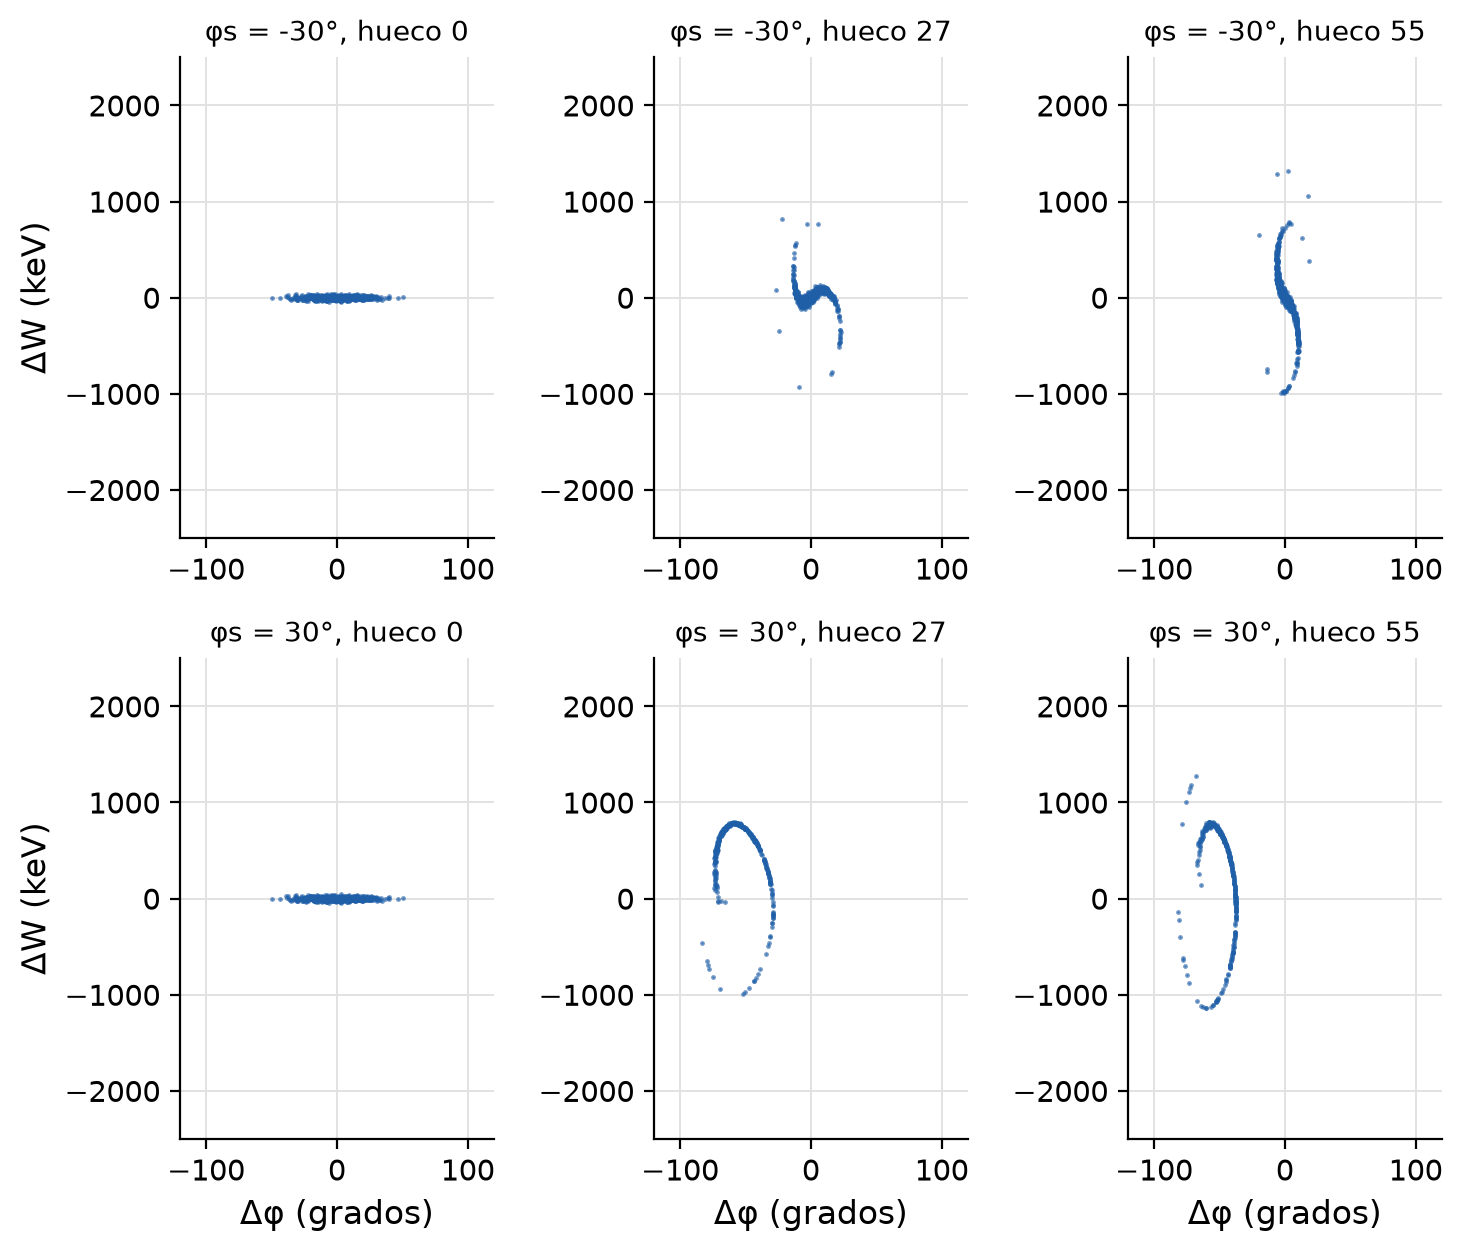

In [35]:
# Fig 2: espacio de fases longitudinal
fig, axs = estilo.figura(2, 3, alto=6.4)
for fila, ps in enumerate((par["fase_referencia_grados"], 30)):
    d = np.load(P.datos / f"paquete_fase{ps}.npz")
    nmax = d["dP"].shape[0] - 1
    for col, k in enumerate((0, nmax // 2, nmax)):
        ax = axs[fila, col]
        ax.plot(d["dP"][k], 1000 * d["dW"][k], ".", ms=1.5, alpha=0.6)
        ax.set_xlim(-120, 120)
        ax.set_ylim(-2500, 2500)
        ax.set_title(f"φs = {ps}°, hueco {k}", fontsize=10)
        if fila == 1:
            ax.set_xlabel("Δφ (grados)")
        if col == 0:
            ax.set_ylabel("ΔW (keV)")
estilo.guardar(fig, P, "fig02_espacio_fases")
display(Image(filename=str(P.figuras / "fig02_espacio_fases.png")))

### Fig 3: oscilaciones de sincrotron

  figura fig03_sincrotron


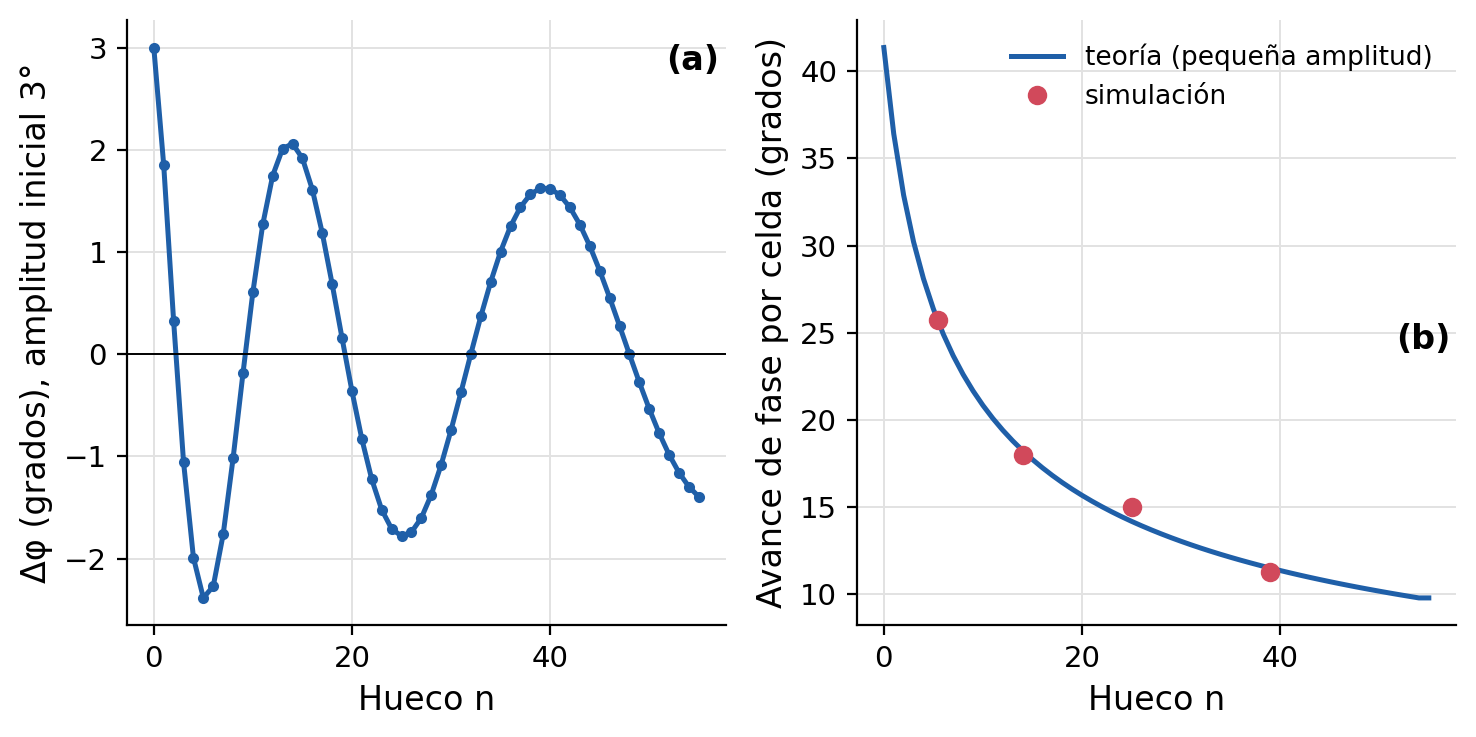

In [13]:
# Fig 3: oscilaciones de sincrotron
O = P.leer_csv("oscilacion_pequena")
MU = P.leer_csv("avance_sincrotron")
EST = P.leer_csv("estabilidad_fase")
fig, axs = estilo.figura(1, 2, alto=3.8)
axs[0].plot(O.celda, O.dphi, "o-", ms=3)
axs[0].axhline(0, color="k", lw=0.7)
axs[0].set_xlabel("Hueco n")
axs[0].set_ylabel("Δφ (grados), amplitud inicial 3°")
estilo.letra(axs[0], "(a)", 0.9)
axs[1].plot(O.celda, np.degrees(O.mu_teo_rad), "-", label="teoría (pequeña amplitud)")
axs[1].plot(MU.celda_media, np.degrees(MU.mu_sim), "o", label="simulación")
axs[1].set_xlabel("Hueco n")
axs[1].set_ylabel("Avance de fase por celda (grados)")
axs[1].legend()
estilo.letra(axs[1], "(b)", 0.9, 0.5)
estilo.guardar(fig, P, "fig03_sincrotron")
display(Image(filename=str(P.figuras / "fig03_sincrotron.png")))

### Fig 4: estabilidad, error de frecuencia y electrones

  figura fig04_estabilidad_electrones


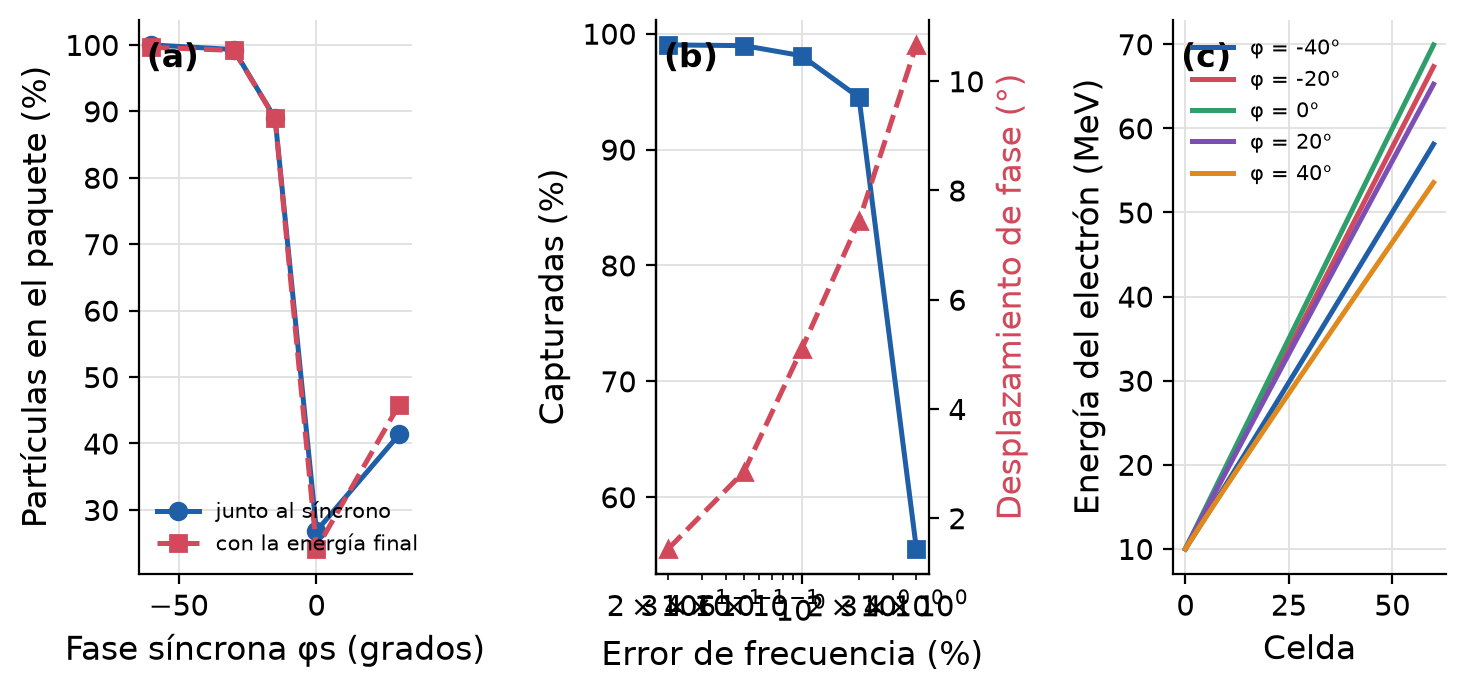

In [36]:
# Fig 4: estabilidad, error de frecuencia y electrones
ER = P.leer_csv("error_frecuencia")
E = P.leer_csv("electrones")
fig, axs = estilo.figura(1, 3, alto=3.6)
axs[0].plot(EST.fase_sincrona, 100 * EST.capturadas, "o-", label="junto al síncrono")
axs[0].plot(EST.fase_sincrona, 100 * EST.aceleradas, "s--", label="con la energía final")
axs[0].legend(fontsize=7.5, loc="lower left")
axs[0].set_xlabel("Fase síncrona φs (grados)")
axs[0].set_ylabel("Partículas en el paquete (%)")
axs[1].semilogx(100 * ER.error_f[1:], 100 * ER.capturadas[1:], "s-", label="capturadas (%)")
axs[1].set_xlabel("Error de frecuencia (%)")
axs[1].set_ylabel("Capturadas (%)")
ax2 = axs[1].twinx()
ax2.semilogx(100 * ER.error_f[1:], ER.fase_media_final[1:], "^--", color="#d1495b")
ax2.set_ylabel("Desplazamiento de fase (°)", color="#d1495b")
ax2.spines["right"].set_visible(True)
ax2.grid(False)
for p in (-40, -20, 0, 20, 40):
    axs[2].plot(E.celda, E[f"T_fase{p}"], label=f"φ = {p}°")
axs[2].set_xlabel("Celda")
axs[2].set_ylabel("Energía del electrón (MeV)")
axs[2].legend(fontsize=7.5)
for ax, l in zip(axs, "abc"):
    estilo.letra(ax, f"({l})", 0.03)
estilo.guardar(fig, P, "fig04_estabilidad_electrones")
display(Image(filename=str(P.figuras / "fig04_estabilidad_electrones.png")))

## 5. Informe y presentación

Escribe `informe/informe.tex` y `informe/presentacion.tex` con los números calculados arriba, los compila con `latexmk` y actualiza el README. Requiere una instalación de LaTeX; si no se dispone de ella, puede omitirse esta celda.

In [37]:
%run src/informe.py

  informe informe.tex


FileNotFoundError: [Errno 2] No such file or directory: 'latexmk'

## 6. Resultados principales

- 3 → 50 MeV, qV = 1 MeV, φs = −30°: 55 celdas, 10.59 m (celdas de 7.7 a 26.9 cm).
- Paquete agrupado: 100.0 % (−60°), 99.3 % (−30°); en la cresta solo 24.1 % llega a la energía final.
- Avance de fase de sincrotrón: 25.7°/celda simulado frente a 26.4° teórico.
- Electrones (β≈1): sin oscilaciones; energía final ∝ cos φ de inyección.